# Iris Flower Classification with Machine Learning (Python, scikit-learn)
Rishabh Aryan — part of the IIT Ropar & NIELIT Ropar 6-Month AI/ML Industrial Training & Certification Program.

EDA → preprocessing → model comparison with cross-validation → hyperparameter tuning → evaluation → interpretation.

Data: Fisher, R. A. (1936). *Iris*. UCI Machine Learning Repository, doi:10.24432/C56C76, CC BY 4.0.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, train_test_split, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from src.data import load_iris_df, FEATURES, SPECIES
SEED = 42
sns.set_theme(style="whitegrid", palette=["#e75480", "#9b6dd6", "#f4a261"])
df = load_iris_df(); df.shape

(150, 5)

## 1. Exploratory data analysis

In [2]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print("missing:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
df["species"].value_counts()

missing: 0 | duplicate rows: 3


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [4]:
df.groupby('species')[FEATURES].agg(['mean','std']).round(2).T

species            Iris-setosa  Iris-versicolor  Iris-virginica
sepal_length mean         5.01             5.94            6.59
             std          0.35             0.52            0.64
sepal_width  mean         3.42             2.77            2.97
             std          0.38             0.31            0.32
petal_length mean         1.46             4.26            5.55
             std          0.17             0.47            0.55
petal_width  mean         0.24             1.33            2.03
             std          0.11             0.20            0.27

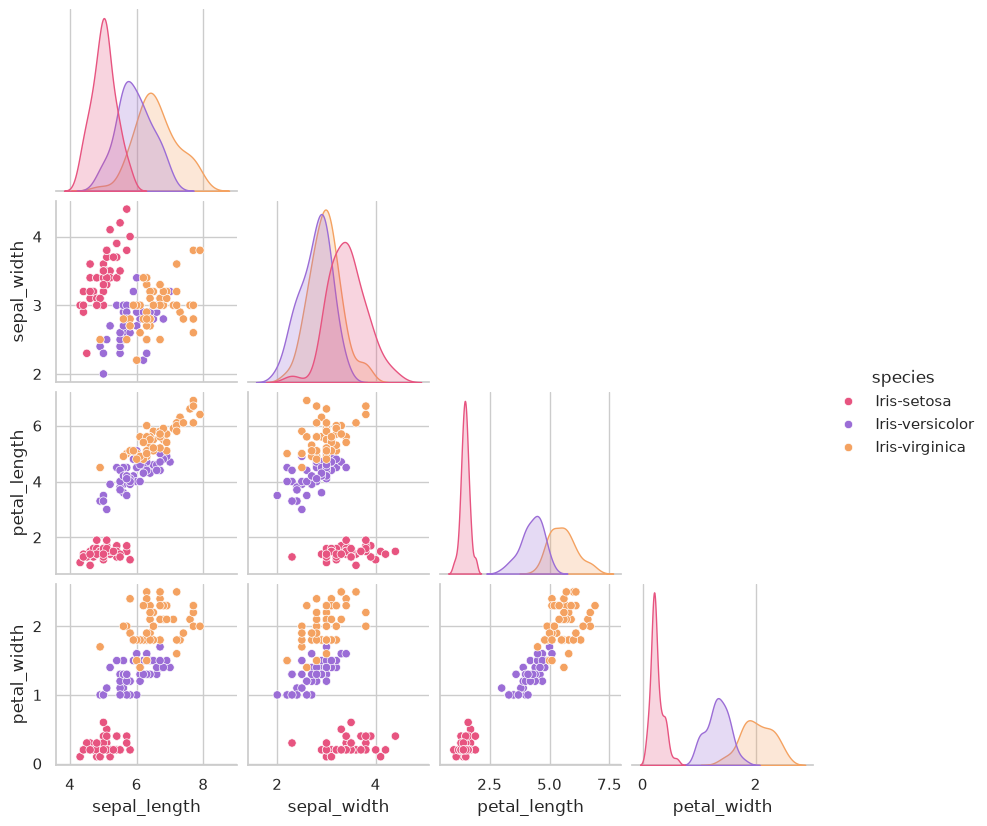

In [5]:
sns.pairplot(df, hue="species", corner=True, height=2.1); plt.show()

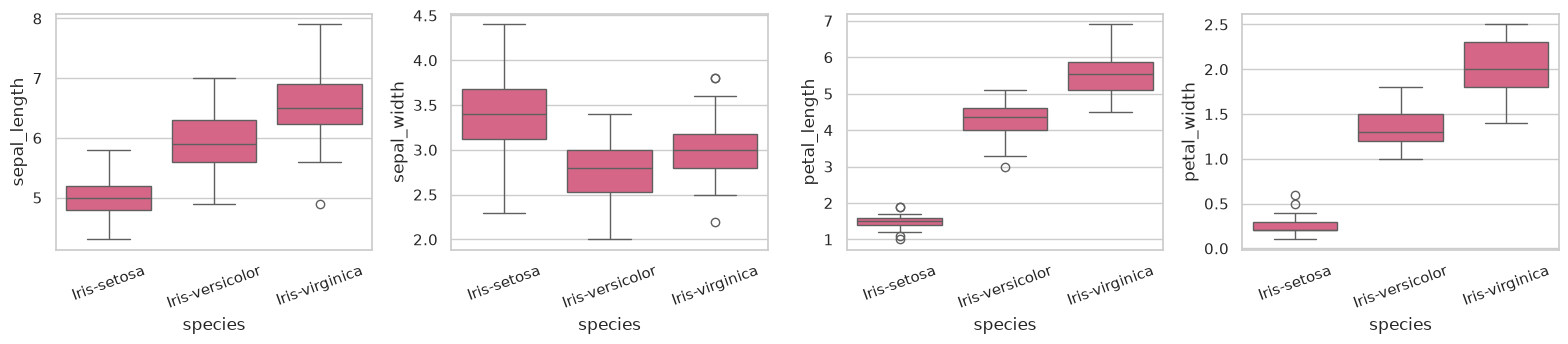

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, f in zip(axes, FEATURES):
    sns.boxplot(data=df, x="species", y=f, ax=ax); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

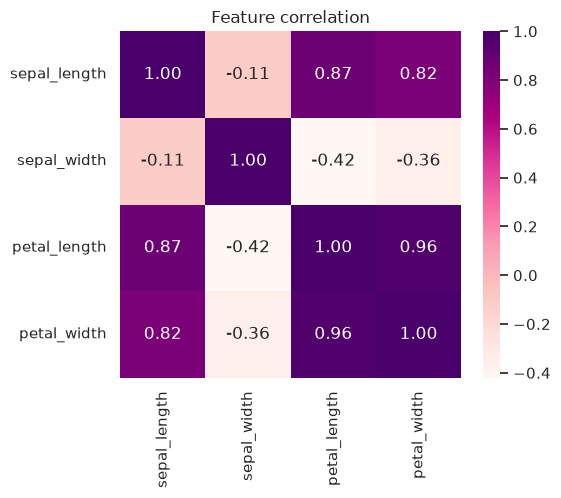

In [7]:
plt.figure(figsize=(5.5,4.5)); sns.heatmap(df[FEATURES].corr(), annot=True, cmap="RdPu", fmt=".2f")
plt.title("Feature correlation"); plt.show()

explained variance ratio: [0.728 0.23 ]


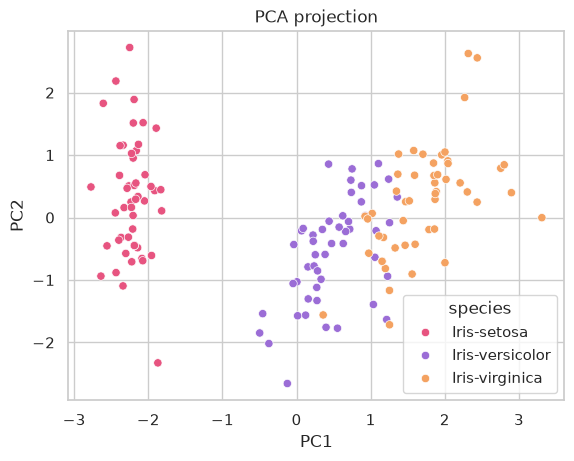

In [8]:
pcs = PCA(2).fit(StandardScaler().fit_transform(df[FEATURES]))
Z = pcs.transform(StandardScaler().fit_transform(df[FEATURES]))
print("explained variance ratio:", pcs.explained_variance_ratio_.round(3))
sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=df["species"]); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA projection"); plt.show()

## 2. Preprocessing
The four features are numeric with no missing values. Standard scaling sits inside each pipeline so it is learned from training folds only. The 3 duplicate rows are kept, as is usual for this dataset (identical measurements of different flowers are plausible at 0.1 cm resolution).

In [9]:
X, y = df[FEATURES].to_numpy(), df["species"].map(SPECIES.index).to_numpy()
pipe = lambda m: Pipeline([("scaler", StandardScaler()), ("clf", m)])

## 3. Model comparison — 10-fold stratified cross-validation

In [10]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
models = {
    "Majority baseline": DummyClassifier(),
    "Logistic regression": LogisticRegression(max_iter=5000),
    "LDA": LinearDiscriminantAnalysis(),
    "K-nearest neighbours": KNeighborsClassifier(),
    "SVM (RBF)": SVC(),
    "Gaussian naive Bayes": GaussianNB(),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
}
res = {n: cross_val_score(pipe(m), X, y, cv=cv) for n, m in models.items()}
table = pd.DataFrame({"accuracy": {n: s.mean() for n, s in res.items()},
                      "std": {n: s.std() for n, s in res.items()}}).sort_values("accuracy", ascending=False).round(3)
table

,accuracy,std
LDA,0.973,0.044
K-nearest neighbours,0.960,0.053
SVM (RBF),0.960,0.044
Logistic regression,0.953,0.052
Random forest,0.953,0.052
Gaussian naive Bayes,0.953,0.052
Decision tree,0.933,0.052
Majority baseline,0.333,0.000


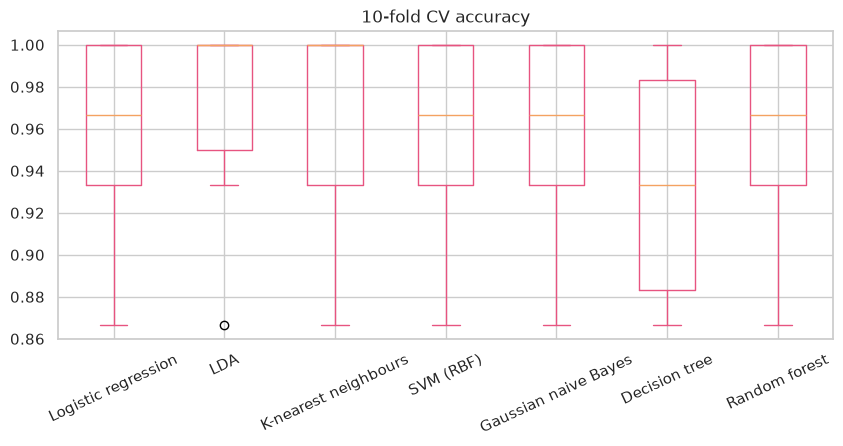

In [11]:
pd.DataFrame(res).drop(columns="Majority baseline").plot.box(figsize=(10,4), rot=25, title="10-fold CV accuracy"); plt.show()

## 4. Hyperparameter tuning
The deployed model is logistic regression, because its parameters export cleanly to JSON for in-browser inference. We tune its regularisation strength `C`, and tune SVM and KNN for comparison.

In [12]:
grids = {
    "Logistic regression": (LogisticRegression(max_iter=5000), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "SVM (RBF)": (SVC(), {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1, 1]}),
    "K-nearest neighbours": (KNeighborsClassifier(), {"clf__n_neighbors": list(range(1, 31, 2))}),
}
tuned = {}
for n, (m, g) in grids.items():
    gs = GridSearchCV(pipe(m), g, cv=cv).fit(X, y)
    tuned[n] = gs
    print(f"{n:22s} best CV accuracy {gs.best_score_:.3f}  params {gs.best_params_}")

Logistic regression    best CV accuracy 0.973  params {'clf__C': 100}


SVM (RBF)              best CV accuracy 0.967  params {'clf__C': 1, 'clf__gamma': 0.1}


K-nearest neighbours   best CV accuracy 0.973  params {'clf__n_neighbors': 13}


## 5. Evaluation
### 5a. Out-of-fold predictions of the tuned logistic regression (every flower predicted by a model that never saw it)

out-of-fold accuracy: 0.973
                 precision    recall  f1-score   support

    Iris-setosa      1.000     1.000     1.000        50
Iris-versicolor      0.979     0.940     0.959        50
 Iris-virginica      0.942     0.980     0.961        50

       accuracy                          0.973       150
      macro avg      0.974     0.973     0.973       150
   weighted avg      0.974     0.973     0.973       150



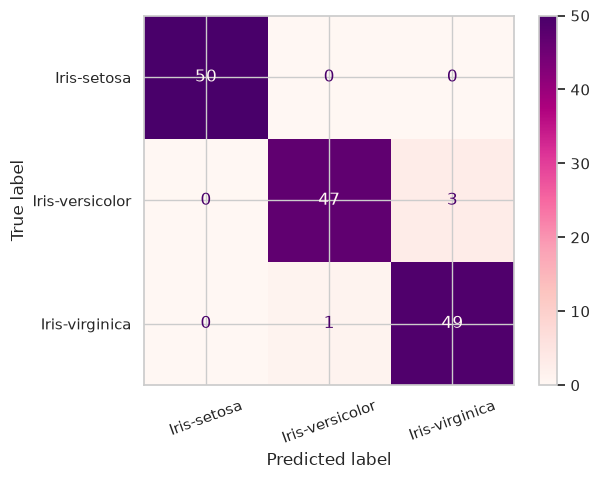

In [13]:
best_lr = tuned["Logistic regression"].best_estimator_
oof = cross_val_predict(best_lr, X, y, cv=cv)
print("out-of-fold accuracy:", round(accuracy_score(y, oof), 3))
print(classification_report(y, oof, target_names=SPECIES, digits=3))
ConfusionMatrixDisplay.from_predictions(y, oof, display_labels=SPECIES, cmap="RdPu", xticks_rotation=20); plt.show()

### 5b. Stratified 70/30 hold-out

In [14]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
m = pipe(LogisticRegression(C=tuned["Logistic regression"].best_params_["clf__C"], max_iter=5000)).fit(X_tr, y_tr)
p = m.predict(X_te)
print("hold-out accuracy:", round(accuracy_score(y_te, p), 3))
print(classification_report(y_te, p, target_names=SPECIES, digits=3))

hold-out accuracy: 0.911
                 precision    recall  f1-score   support

    Iris-setosa      1.000     1.000     1.000        15
Iris-versicolor      0.789     1.000     0.882        15
 Iris-virginica      1.000     0.733     0.846        15

       accuracy                          0.911        45
      macro avg      0.930     0.911     0.910        45
   weighted avg      0.930     0.911     0.910        45



## 6. Interpretation

Standardised coefficients (log-odds per 1 SD):


,sepal_length,sepal_width,petal_length,petal_width
Iris-setosa,-2.80,2.87,-5.72,-5.32
Iris-versicolor,2.23,-0.43,-3.07,-2.30
Iris-virginica,0.57,-2.44,8.79,7.62


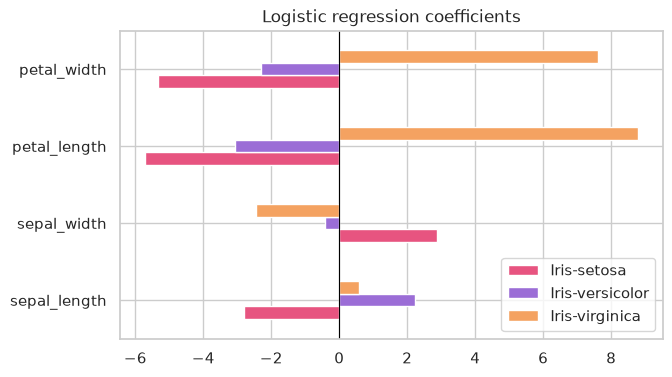

In [15]:
final = best_lr.fit(X, y)
coef = pd.DataFrame(final.named_steps["clf"].coef_, index=SPECIES, columns=FEATURES).round(2)
print("Standardised coefficients (log-odds per 1 SD):"); display(coef)
coef.T.plot.barh(figsize=(7,4), title="Logistic regression coefficients"); plt.axvline(0, color="k", lw=.8); plt.show()

In [16]:
rf = pipe(RandomForestClassifier(n_estimators=300, random_state=SEED)).fit(X, y)
pd.Series(rf.named_steps["clf"].feature_importances_, index=FEATURES).sort_values().round(3)

sepal_width     0.021
sepal_length    0.107
petal_width     0.417
petal_length    0.455
dtype: float64

## 7. Takeaways
* Setosa is linearly separable from the other two species; all confusion is between versicolor and virginica.
* Petal measurements carry most of the signal (pairplot, coefficients and random-forest importances agree).
* Several models reach similar CV accuracy; differences are within one fold-to-fold standard deviation, so the simple, exportable logistic regression is used for the API and the in-browser demo.